# Lecture 12: Feature importances and model interpretation

[Lecture notes](https://ubc-cs.github.io/cpsc330-book/book/12_feat-importances.html)

- **Association:** relationships in the data $\to$ correlation.
- **Global:** how a model uses inputs overall $\to$ coefficients and importance.
- **Local:** what contributed to one prediction $\to$ SHAP.
- **Key distinction:** explaining a model does not establish causation.

**Discuss:** Does strong predictive performance make a model suitable for automatic loan rejection?

## Setup and imports

- Kernel: this directory's `.venv`; run cells in order.
- Data: `data/housing-kaggle/train.csv` and `data/adult.csv`.
- Dependencies: LightGBM and SHAP.
- Use validation data for interpretation; reserve test data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from lightgbm import LGBMClassifier
import shap

%matplotlib inline
DATA_DIR = Path("data")
plt.rcParams.update({"figure.figsize": (8, 4)})

for relative_path in ["housing-kaggle/train.csv", "adult.csv"]:
    data_path = DATA_DIR / relative_path
    if not data_path.is_file():
        raise FileNotFoundError(f"Place the dataset at {data_path.resolve()} and run from content/classes/varada.")

## 1. Housing data and preprocessing

- **Target:** `SalePrice` in dollars; reserve 10% for testing.
- **Numeric:** median imputation + missing indicators → scaling.
- **Ordinal:** imputation → ordered codes → scaling.
- **Categorical:** fill unknowns → one-hot encoding; drop `Id`.
- Preserve `None`; distinguish **absent amenities** from unknown ratings.
- Learn imputation and scaling inside each pipeline.

In [2]:
df = pd.read_csv(
    DATA_DIR / "housing-kaggle/train.csv",
    keep_default_na=False,
    na_values=["", "NA"],
)
train_df, test_df = train_test_split(df, test_size=0.10, random_state=123)


X_train = train_df.drop(columns=["SalePrice"])
y_train = train_df["SalePrice"]

X_test = test_df.drop(columns=["SalePrice"])
y_test = test_df["SalePrice"]



def mark_absent_amenities(X):
    X = X.copy()
    amenity_columns = {
        "TotalBsmtSF": ["BsmtQual", "BsmtCond", "BsmtExposure",
                        "BsmtFinType1", "BsmtFinType2"],
        "Fireplaces": ["FireplaceQu"],
        "GarageArea": ["GarageType", "GarageFinish", "GarageQual", "GarageCond"],
        "PoolArea": ["PoolQC"],
    }
    for measurement, columns in amenity_columns.items():
        absent = X[measurement].eq(0)
        X.loc[absent, columns] = X.loc[absent, columns].fillna("Absent")

    for column in ["Alley", "Fence", "MiscFeature"]:
        X[column] = X[column].fillna("Absent")
    return X


X_train = mark_absent_amenities(X_train)
X_test = mark_absent_amenities(X_test)


drop_features = ["Id"]
numeric_features = [
    "BedroomAbvGr",
    "KitchenAbvGr",
    "LotFrontage",
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageYrBlt",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "YrSold",
]

ordinal_features_reg = ["ExterQual", "ExterCond", "HeatingQC", "KitchenQual"]
ordering = ["Po", "Fa", "TA", "Gd", "Ex"]
ordering_ordinal_reg = [ordering] * len(ordinal_features_reg)

ordinal_features_oth = ["Functional"]
ordering_ordinal_oth = [
    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
]

assigned_features = (
    drop_features + numeric_features + ordinal_features_reg + ordinal_features_oth
)
categorical_features = [
    column for column in X_train.columns if column not in assigned_features
]

numeric_transformer = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
)
ordinal_transformer_reg = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_reg),
    StandardScaler(),
)
ordinal_transformer_oth = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_oth),
    StandardScaler(),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="Unknown"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    ("drop", drop_features),
    (numeric_transformer, numeric_features),
    (ordinal_transformer_reg, ordinal_features_reg),
    (ordinal_transformer_oth, ordinal_features_oth),
    (categorical_transformer, categorical_features),
    verbose_feature_names_out=False,
)

## 2. Correlation describes the data

- Pearson correlation measures **pairwise linear association**.
- Near ±1: strong linear association; near 0 can hide nonlinearity.
- Inspect training data only.

**Predict:** Will larger houses tend to have higher prices?

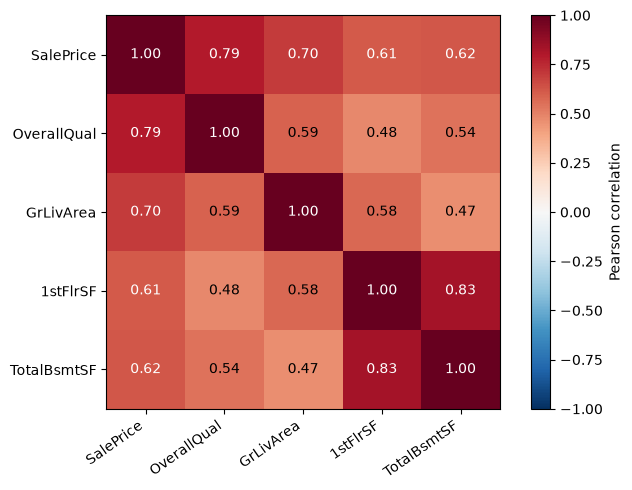

In [3]:
corr_columns = ["SalePrice", "OverallQual", "GrLivArea", "1stFlrSF", "TotalBsmtSF"]
corr = train_df[corr_columns].corr()
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for row in range(len(corr)):
    for col in range(len(corr)):
        ax.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[row, col]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

- Compare `GrLivArea` and `SalePrice`; `1stFlrSF` and `TotalBsmtSF`.
- Related features may supply overlapping information.
- **Correlation does not explain how a fitted model combines inputs.**

## 3. Interpret ridge coefficients

$$\hat{y} = b + \sum_j w_j z_j$$

- $z_j$ is a **transformed input**; increasing it by 1 changes the prediction by $w_j$.
- Hold other transformed inputs fixed; read the preprocessing first.
- Compare ridge (`alpha=100`) with a mean baseline using five-fold CV.
- Check mean validation R² and variation across folds.

In [4]:
house_pipe = make_pipeline(clone(preprocessor), Ridge(alpha=100))
house_scores = {}
for name, estimator in {
    "Predict training mean": DummyRegressor(),
    "Ridge": house_pipe,
}.items():
    scores = cross_validate(estimator, X_train, y_train, cv=5, scoring="r2")
    house_scores[name] = {
        "Mean validation R2": scores["test_score"].mean(),
        "SD across folds": scores["test_score"].std(),
    }
pd.DataFrame(house_scores).T

,Mean validation R2,SD across folds
Predict training mean,-0.005307,0.005636
Ridge,0.797221,0.097971


In [5]:
house_pipe.fit(X_train, y_train)
house_preprocessor = house_pipe.named_steps["columntransformer"]
house_coefs = pd.Series(
    house_pipe.named_steps["ridge"].coef_,
    index=house_preprocessor.get_feature_names_out(),
    name="Coefficient",
)
house_coefs.reindex(house_coefs.abs().sort_values(ascending=False).index).head(10)

OverallQual             14071.079678
GrLivArea               11501.817023
BsmtQual_Ex             11170.908367
Neighborhood_NoRidge     9373.965731
Neighborhood_NridgHt     8397.405152
GarageCars               8262.693270
2ndFlrSF                 8075.399323
BsmtExposure_Gd          7305.454377
Condition1_Norm          7145.332642
1stFlrSF                 6681.399715
Name: Coefficient, dtype: float64

In [6]:
house_coefs["LotArea"]

np.float64(3421.8648055767476)

### Numeric features: account for scaling

- One standardized unit = **one fitted training standard deviation**.
- Illustrative scale = $2,000$ sq ft, coefficient = $\$10,000 \to +1,000$ sq ft gives $+\$5,000$.
- Retrieve the actual scale and names from **this fitted pipeline**.
- Coefficient magnitudes mix different kinds of changes; they are not universal importance scores.

In [7]:
numeric_branch = house_preprocessor.named_transformers_["pipeline-1"]
numeric_names = numeric_branch.named_steps["simpleimputer"].get_feature_names_out(numeric_features)
numeric_scales = pd.Series(
    numeric_branch.named_steps["standardscaler"].scale_, index=numeric_names
)
area_scale = numeric_scales["LotArea"]
area_coef = house_coefs["LotArea"]
pd.Series({
    "Training scale in square feet": area_scale,
    "Dollars per scaled unit": area_coef,
    "Dollars per additional square foot": area_coef / area_scale,
})

Training scale in square feet         8994.471032
Dollars per scaled unit               3421.864806
Dollars per additional square foot       0.380441
dtype: float64

**Predict:** Add 1,000 sq ft to `LotArea`. How much does the prediction change?

$$\text{change in prediction} = \text{coefficient}\times\frac{\text{change in original input}}{\text{fitted scale}}.$$

- Edit an observed value; keep its missing indicator unchanged.
- Check the calculation against pipeline predictions.

In [8]:
house = X_train.loc[X_train["LotArea"].notna()].iloc[[0]].copy()
larger_lot = house.copy()
larger_lot["LotArea"] += 1000
area_expected = area_coef * 1000 / area_scale
area_actual = (house_pipe.predict(larger_lot) - house_pipe.predict(house))[0]
np.testing.assert_allclose(area_actual, area_expected)
pd.Series({"Change from coefficient ($)": area_expected,
           "Change from predictions ($)": area_actual})

Change from coefficient ($)    380.440917
Change from predictions ($)    380.440917
dtype: float64

### Ordinal features: encoding + scaling

- `ExterQual`: `Po < Fa < TA < Gd < Ex` $\to$ integer codes $\to$ scaling.
- **Equal spacing is a modelling assumption**, preserved by scaling.

**Predict:** Do `Gd` $\to$ `Ex` and `TA` $\to$ `Gd` give the same prediction change?

In [9]:
ordinal_scale = pd.Series(
    house_preprocessor.named_transformers_["pipeline-2"].named_steps["standardscaler"].scale_,
    index=ordinal_features_reg,
)
good_house = X_train.loc[X_train["ExterQual"].eq("Gd")].iloc[[0]].copy()
excellent_house = good_house.copy()
excellent_house["ExterQual"] = "Ex"
quality_expected = house_coefs["ExterQual"] / ordinal_scale["ExterQual"]
quality_actual = (house_pipe.predict(excellent_house) - house_pipe.predict(good_house))[0]
np.testing.assert_allclose(quality_actual, quality_expected)
pd.Series({"Change from coefficient ($)": quality_expected,
           "Change from predictions ($)": quality_actual})

Change from coefficient ($)    9700.424021
Change from predictions ($)    9700.424021
dtype: float64

### Categorical features: compare two coefficients

- All one-hot categories are retained.
- `Gtl` $\to$ `Mod`: Gentle indicator **1 $\to$ 0**, Moderate indicator **0 $\to$ 1**.

$$\text{change in prediction} = w_{\text{LandSlope\_Mod}} - w_{\text{LandSlope\_Gtl}}$$

- With a dropped reference category, compare against that reference.

In [10]:
slope_coefs = house_coefs[house_coefs.index.str.startswith("LandSlope_")]
pd.DataFrame({
    "Coefficient": slope_coefs,
    "Difference from Gentle ($)": slope_coefs - slope_coefs["LandSlope_Gtl"],
})

,Coefficient,Difference from Gentle ($)
LandSlope_Gtl,-2365.345172,0.000000
LandSlope_Mod,3174.619024,5539.964196
LandSlope_Sev,-809.273853,1556.071319


In [11]:
gentle_house = X_train.loc[X_train["LandSlope"].eq("Gtl")].iloc[[0]].copy()
moderate_house = gentle_house.copy()
moderate_house["LandSlope"] = "Mod"
slope_expected = slope_coefs["LandSlope_Mod"] - slope_coefs["LandSlope_Gtl"]
slope_actual = (house_pipe.predict(moderate_house) - house_pipe.predict(gentle_house))[0]
np.testing.assert_allclose(slope_actual, slope_expected)
pd.Series({"Change from coefficients ($)": slope_expected,
           "Change from predictions ($)": slope_actual})

Change from coefficients ($)    5539.964196
Change from predictions ($)     5539.964196
dtype: float64

### Coefficient takeaways

- Account for **scaling, encoding, and output units**.
- Correlated inputs can share weight differently across fitted models.
- Regularization and the included features affect coefficients.
- **Prediction checks verify model arithmetic, not renovation effects.**

## 4. Adult data: fit models for interpretation

- **Target:** income `>50K` = class 1; historical census data.
- Reserve 20% for testing; split remaining data into fitting/validation sets.
- **Numeric:** standardize; **education:** ordinal encode without scaling.
- **Sex:** binary indicator; **other categories:** impute + one-hot encode.
- Drop `fnlwgt`, `race`, `education.num`; replace `?` with missing values.
- **Dropping race does not establish fairness.**

In [12]:
adult = pd.read_csv(DATA_DIR / "adult.csv")
adult_development, adult_test = train_test_split(adult, test_size=0.2, random_state=42)
adult_fit, adult_valid = train_test_split(
    adult_development, test_size=0.25, random_state=123,
    stratify=adult_development["income"],
)
adult_fit = adult_fit.replace("?", np.nan)
adult_valid = adult_valid.replace("?", np.nan)

numeric_features = ["age", "capital.gain", "capital.loss", "hours.per.week"]

categorical_features = [
    "workclass",
    "marital.status",
    "occupation",
    "relationship",
    "native.country",
]

ordinal_features = ["education"]
binary_features = ["sex"]
drop_features = ["fnlwgt", "race", "education.num"]
target_column = "income"
education_levels = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate",
]
numeric_transformer = StandardScaler()

ordinal_transformer = OrdinalEncoder(categories=[education_levels], dtype=int)

binary_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(drop="if_binary", dtype=int),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

adult_preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (ordinal_transformer, ordinal_features),
    (binary_transformer, binary_features),
    (categorical_transformer, categorical_features),
    ("drop", drop_features),
    verbose_feature_names_out=False,
)

assert set(adult_fit["income"]) == {"<=50K", ">50K"}
X_adult_fit = adult_fit.drop(columns="income")
X_adult_valid = adult_valid.drop(columns="income")
y_adult_fit = adult_fit["income"].eq(">50K").astype(int)
y_adult_valid = adult_valid["income"].eq(">50K").astype(int)

### Compare a baseline and three models

- Majority class, logistic regression, random forest, LightGBM.
- Each pipeline gets its **own cloned preprocessor**.
- Compare validation accuracy and the training–validation gap.
- Fixed settings; accuracy follows Chapter 11.

In [13]:
adult_models = {
    "Logistic regression": make_pipeline(
        clone(adult_preprocessor), LogisticRegression(max_iter=2000)
    ),
    "Random forest": make_pipeline(
        clone(adult_preprocessor),
        RandomForestClassifier(n_estimators=100, random_state=123, n_jobs=1),
    ),
    "LightGBM": make_pipeline(
        clone(adult_preprocessor),
        LGBMClassifier(random_state=123, verbosity=-1, n_jobs=1),
    ),
}
baseline = DummyClassifier(strategy="most_frequent").fit(X_adult_fit, y_adult_fit)
adult_scores = {"Majority class": {
    "Training accuracy": baseline.score(X_adult_fit, y_adult_fit),
    "Validation accuracy": baseline.score(X_adult_valid, y_adult_valid),
}}
for name, pipe in adult_models.items():
    pipe.fit(X_adult_fit, y_adult_fit)
    adult_scores[name] = {
        "Training accuracy": pipe.score(X_adult_fit, y_adult_fit),
        "Validation accuracy": pipe.score(X_adult_valid, y_adult_valid),
    }
pd.DataFrame(adult_scores).T.round(3)

,Training accuracy,Validation accuracy
Majority class,0.758,0.758
Logistic regression,0.855,0.853
Random forest,0.978,0.852
LightGBM,0.889,0.869


### Logistic regression coefficients

- Positive coefficient → higher score and probability of `>50K`, other inputs fixed.
- **Units: log-odds**, not probability increments.
- Numeric: one training SD; education: one unscaled code step.
- Probability change depends on the starting score.

In [14]:
adult_lr = adult_models["Logistic regression"]
adult_lr_coefs = pd.Series(
    adult_lr.named_steps["logisticregression"].coef_[0],
    index=adult_lr.named_steps["columntransformer"].get_feature_names_out(),
    name="Log-odds coefficient",
)
adult_lr_coefs.reindex(adult_lr_coefs.abs().sort_values(ascending=False).index).head(8)

capital.gain                        2.305364
marital.status_Married-AF-spouse    1.876896
occupation_Priv-house-serv         -1.540356
marital.status_Never-married       -1.426234
relationship_Own-child             -1.333088
native.country_Columbia            -1.174423
native.country_Greece              -1.090200
relationship_Wife                   1.006413
Name: Log-odds coefficient, dtype: float64

## 5. Global feature importance

### Impurity-based importance

- Credits features for **training impurity reductions**, weighted by samples reaching each split.
- Forest combines contributions across trees; values sum to 1 here.
- Magnitude only: no upward/downward direction.
- Can favour features with many possible split points and reward overfitting.

**Inspect:** Which transformed column ranks highest?

In [15]:
forest_pipe = adult_models["Random forest"]
forest_names = forest_pipe.named_steps["columntransformer"].get_feature_names_out()
impurity_importance = pd.Series(
    forest_pipe.named_steps["randomforestclassifier"].feature_importances_,
    index=forest_names,
).sort_values(ascending=False)
impurity_importance

age                                          2.286793e-01
education                                    1.314283e-01
hours.per.week                               1.119088e-01
capital.gain                                 1.100454e-01
marital.status_Married-civ-spouse            7.714507e-02
                                                 ...     
workclass_Without-pay                        4.703491e-05
native.country_Outlying-US(Guam-USVI-etc)    3.496626e-05
native.country_Honduras                      1.053838e-05
occupation_Armed-Forces                      1.836657e-06
workclass_Never-worked                       3.021796e-07
Length: 84, dtype: float64

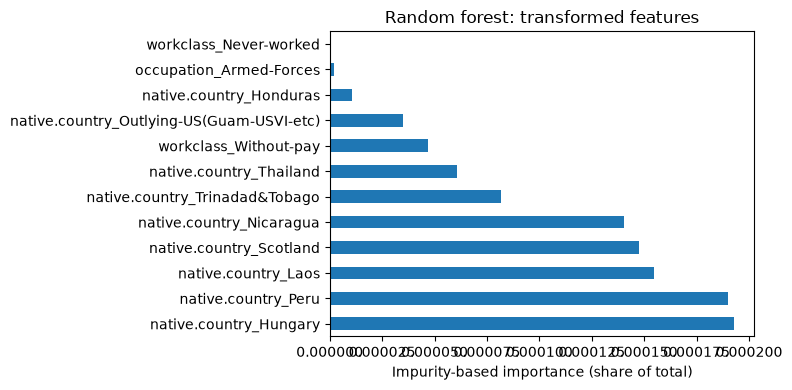

In [16]:
impurity_importance.tail(12).plot.barh()
plt.xlabel("Impurity-based importance (share of total)")
plt.title("Random forest: transformed features")
plt.tight_layout()
plt.show()

### Permutation importance: validation data

$$\text{importance} = \text{original score} - \text{score after shuffling}$$

- Shuffle one **original column**; repeat scoring **without refitting**.
- Model agnostic; full pipeline keeps one-hot groups consistent.
- Accuracy decrease of **0.02 = 2 percentage points**.
- Compare forest and LightGBM on the same validation subset.

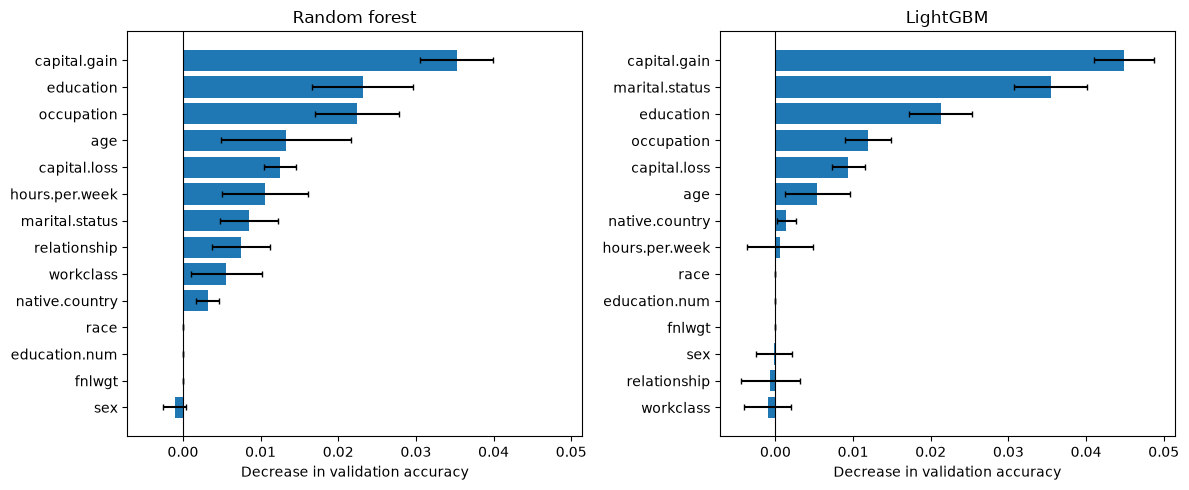

In [17]:
# Use a reproducible validation subset to keep repeated scoring manageable.
X_inspect = X_adult_valid.sample(n=min(1500, len(X_adult_valid)), random_state=123)
y_inspect = y_adult_valid.loc[X_inspect.index]
permutation_results = {}
for name in ["Random forest", "LightGBM"]:
    permutation_results[name] = permutation_importance(
        adult_models[name], X_inspect, y_inspect,
        scoring="accuracy", n_repeats=10, random_state=123, n_jobs=1,
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (name, result) in zip(axes, permutation_results.items()):
    order = result.importances_mean.argsort()
    ax.barh(X_inspect.columns[order], result.importances_mean[order],
            xerr=result.importances_std[order], capsize=2)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Decrease in validation accuracy")
plt.tight_layout()
plt.show()

### Compare the rankings

- **Impurity:** training splits, transformed columns.
- **Permutation:** held-out score decrease, original columns.
- Error bars: one SD across shuffles; small negatives can occur by chance.
- Dropped columns have zero importance; correlated inputs may substitute.
- **Low importance $\neq$ safe to delete:** evaluate a refitted pipeline.

**Discuss:** Do the rankings agree? Why might two related features both rank low?

## 6. Explain individual predictions with SHAP

How does each feature contribute to one prediction?

$$f(x) = \text{base value} + \sum_j \phi_j(x)$$

- **Background**: 100 sampled training examples used as the comparison population.
- **Base value**: the model's average score on the background examples.
- **SHAP value $\phi_j(x)$**: feature $j$'s contribution to this individual's score.
  - Positive contributions increase the score; negative contributions decrease it.
- Here, $f(x)$ is the model's raw score (log-odds of income `>50K`).
- SHAP explains the model's prediction; it does not establish cause and effect.

In [18]:
lgbm_pipe = adult_models["LightGBM"]
lgbm_preprocessor = lgbm_pipe.named_steps["columntransformer"]
lgbm_model = lgbm_pipe.named_steps["lgbmclassifier"]
lgbm_names = lgbm_preprocessor.get_feature_names_out()

def encode_for_lgbm(frame):
    return pd.DataFrame(lgbm_preprocessor.transform(frame),
                        columns=lgbm_names, index=frame.index)

background = encode_for_lgbm(X_adult_fit.sample(n=100, random_state=123))
X_explain_raw = X_adult_valid.sample(n=300, random_state=123)
X_explain = encode_for_lgbm(X_explain_raw)
explainer = shap.TreeExplainer(
    lgbm_model,
    data=background,
    model_output="raw",
)
shap_values = explainer(X_explain)
shap_values.shape

(300, 84)

In [37]:
lgbm_names.tolist()

['age',
 'capital.gain',
 'capital.loss',
 'hours.per.week',
 'education',
 'sex_Male',
 'workclass_Federal-gov',
 'workclass_Local-gov',
 'workclass_Never-worked',
 'workclass_Private',
 'workclass_Self-emp-inc',
 'workclass_Self-emp-not-inc',
 'workclass_State-gov',
 'workclass_Without-pay',
 'workclass_missing',
 'marital.status_Divorced',
 'marital.status_Married-AF-spouse',
 'marital.status_Married-civ-spouse',
 'marital.status_Married-spouse-absent',
 'marital.status_Never-married',
 'marital.status_Separated',
 'marital.status_Widowed',
 'occupation_Adm-clerical',
 'occupation_Armed-Forces',
 'occupation_Craft-repair',
 'occupation_Exec-managerial',
 'occupation_Farming-fishing',
 'occupation_Handlers-cleaners',
 'occupation_Machine-op-inspct',
 'occupation_Other-service',
 'occupation_Priv-house-serv',
 'occupation_Prof-specialty',
 'occupation_Protective-serv',
 'occupation_Sales',
 'occupation_Tech-support',
 'occupation_Transport-moving',
 'occupation_missing',
 'relationshi

In [38]:
pd.DataFrame(shap_values.values, columns=lgbm_names.tolist())

,age,capital.gain,capital.loss,hours.per.week,education,sex_Male,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_missing
0,0.016646,-0.410080,-0.021137,0.261726,-0.516060,-0.212035,-0.005899,0.009164,0.0,-0.007136,...,0.0,0.0,0.0,0.0,0.0,0.0,0.001825,0.0,0.0,-0.001873
1,0.958673,-0.262641,-0.015982,0.484934,1.150012,0.092422,-0.009974,0.008721,0.0,-0.057897,...,0.0,0.0,0.0,0.0,0.0,0.0,0.010928,0.0,0.0,0.008665
2,-2.928029,-0.334011,-0.030235,-0.112899,-0.443997,-0.079106,-0.003968,0.005691,0.0,0.002528,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.000707,0.0,0.0,-0.021405
3,-3.495128,-0.402509,-0.043310,-0.087787,-0.730664,0.072159,-0.005960,0.008011,0.0,-0.006428,...,0.0,0.0,0.0,0.0,0.0,0.0,0.010201,0.0,0.0,0.008766
4,0.815083,-0.349628,-0.011741,-0.088073,0.586411,-0.604121,-0.005930,-0.364932,0.0,-0.011786,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.002177,0.0,0.0,0.006571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,0.289317,-0.397049,-0.028334,0.018991,-0.400583,-0.098726,-0.010158,0.002341,0.0,-0.006358,...,0.0,0.0,0.0,0.0,0.0,0.0,0.011382,0.0,0.0,0.001991
296,0.173014,-0.451747,-0.027469,0.000137,0.016437,-0.064910,-0.006313,0.002970,0.0,-0.012637,...,0.0,0.0,0.0,0.0,0.0,0.0,0.003697,0.0,0.0,0.003097
297,0.624546,-0.349963,-0.018808,-0.798015,-0.199112,-0.302031,-0.004031,0.006392,0.0,0.051559,...,0.0,0.0,0.0,0.0,0.0,0.0,0.004150,0.0,0.0,-0.001641
298,-0.564994,-0.484812,-0.023471,-0.946868,-0.068858,0.072011,-0.006995,0.006817,0.0,0.021974,...,0.0,0.0,0.0,0.0,0.0,0.0,0.005438,0.0,0.0,0.005907


### Check the output and units

- `model_output="raw"`: explain **log-odds of `>50K`**.
- **Odds** compare the probability of `>50K` with the probability of `<=50K`: $p/(1-p)$. For example, $p=0.8$ gives odds of $4:1$.
- **Log-odds** are the natural log of the odds: $s=\ln(p/(1-p))$. Think of this as a score: zero means 50% probability, positive means above 50%, and negative means below 50%.
- **Base value:** mean raw output on the background, not class frequency.
- Check: base + contributions = model raw score.
- Positive SHAP values push the predicted probability upward; negative values push it downward. Their sizes are in **log-odds**, so they are not percentage-point changes in probability.
- Add the base value and contributions first, then apply sigmoid to the **total score** to get the predicted probability.

$$P(\text{class 1}) = \frac{1}{1+e^{-s}}$$

- $s=-2\rightarrow P\approx0.12$
- $s=0\rightarrow P=0.5$ 
- $s=2\rightarrow P\approx0.88$

The same $+1$ contribution has a different probability impact depending on the starting score: $0\to1$ means approximately 50% to 73%, while $2\to3$ means approximately 88% to 95%.

In [20]:
raw_scores = lgbm_model.predict(X_explain, raw_score=True)
reconstructed_scores = shap_values.base_values + shap_values.values.sum(axis=1)
np.testing.assert_allclose(reconstructed_scores, raw_scores, atol=1e-5)
np.testing.assert_allclose(
    shap_values.base_values, lgbm_model.predict(background, raw_score=True).mean(),
    atol=1e-5,
)
np.testing.assert_allclose(
    1 / (1 + np.exp(-raw_scores)),
    lgbm_pipe.predict_proba(X_explain_raw)[:, 1],
)
pd.DataFrame({
    "Base + contributions": reconstructed_scores,
    "Model raw score": raw_scores,
    "Probability of >50K": lgbm_pipe.predict_proba(X_explain_raw)[:, 1],
}, index=X_explain_raw.index).head()

,Base + contributions,Model raw score,Probability of >50K
15099,-4.318873,-4.318873,0.013140
14468,1.960487,1.960487,0.876586
29983,-7.779282,-7.779282,0.000418
28587,-5.918548,-5.918548,0.002682
32139,-3.078843,-3.078843,0.043988


### Read two waterfall plots

- Lowest- and highest-probability rows in the validation sample.
- Deliberately contrasting examples; not typical cases or proof of correctness.

In [21]:
probabilities = lgbm_pipe.predict_proba(X_explain_raw)[:, 1]
low_position = int(np.argmin(probabilities))
high_position = int(np.argmax(probabilities))
positions = [low_position, high_position]
example_summary = X_explain_raw.iloc[positions][
    ["age", "education", "occupation", "capital.gain", "hours.per.week"]
].copy()
example_summary["Observed class (1 = >50K)"] = y_adult_valid.loc[example_summary.index]
example_summary["Predicted probability of >50K"] = probabilities[positions]
example_summary

,age,education,occupation,capital.gain,hours.per.week,Observed class (1 = >50K),Predicted probability of >50K
22755,17,11th,Adm-clerical,0,16,0,0.000339
1671,38,Masters,Exec-managerial,99999,70,1,0.999016


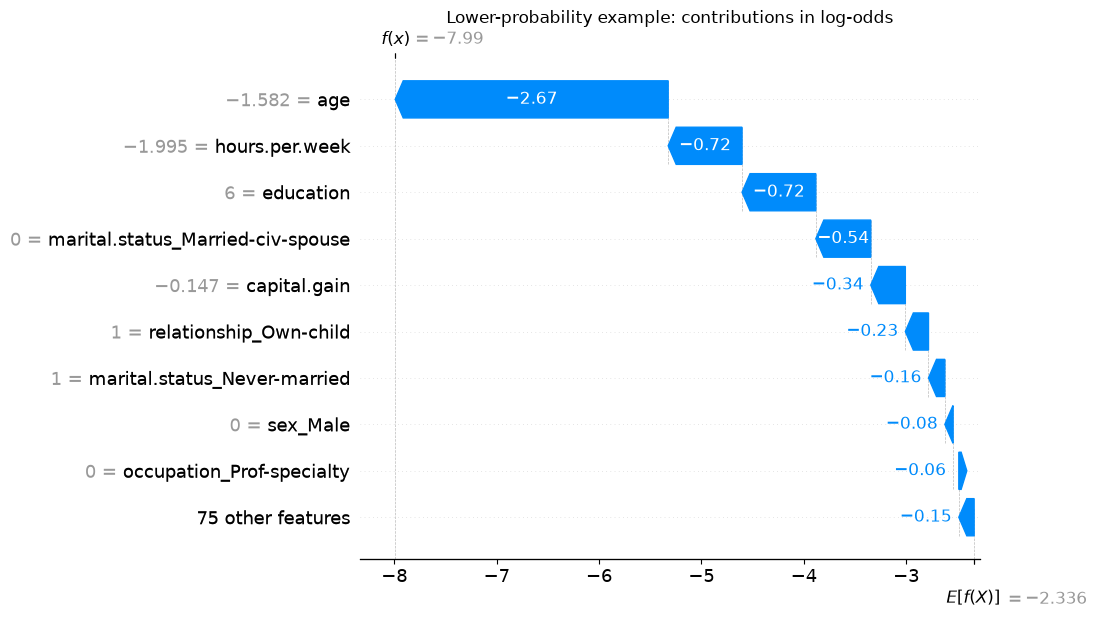

In [22]:
shap.plots.waterfall(shap_values[low_position], max_display=10, show=False)
plt.title("Lower-probability example: contributions in log-odds")
plt.show()

- **Axis:** raw score (log-odds); negative score → probability below 0.5.
- **Red:** raises output; **blue:** lowers output from the base.
- Displayed inputs are transformed; standardized age is not years.
- An absent one-hot category can receive a contribution.
- Final grouped row combines smaller contributions.

**Inspect:** Which inputs contribute most to this prediction?

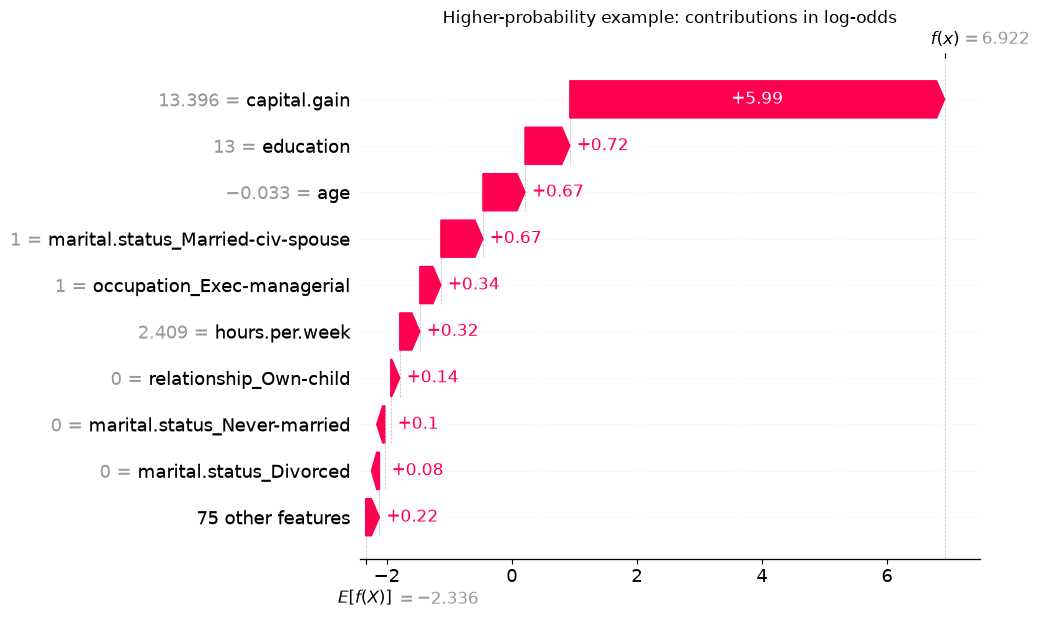

In [23]:
shap.plots.waterfall(shap_values[high_position], max_display=10, show=False)
plt.title("Higher-probability example: contributions in log-odds")
plt.show()

- Same reference, different feature values and contributions.
- Compare the largest contributions with the first example.
- Capital gain: dollars in the table, standardized units in the plot.
- **A contribution is not a recommendation to change a feature.**

### SHAP bar plot: summarize local explanations

- Mean **absolute** contribution across explained rows.
- Positive and negative contributions do not cancel.
- Units: **log-odds**, not accuracy decrease; no label comparison.
- Describes this sample, background, and representation.

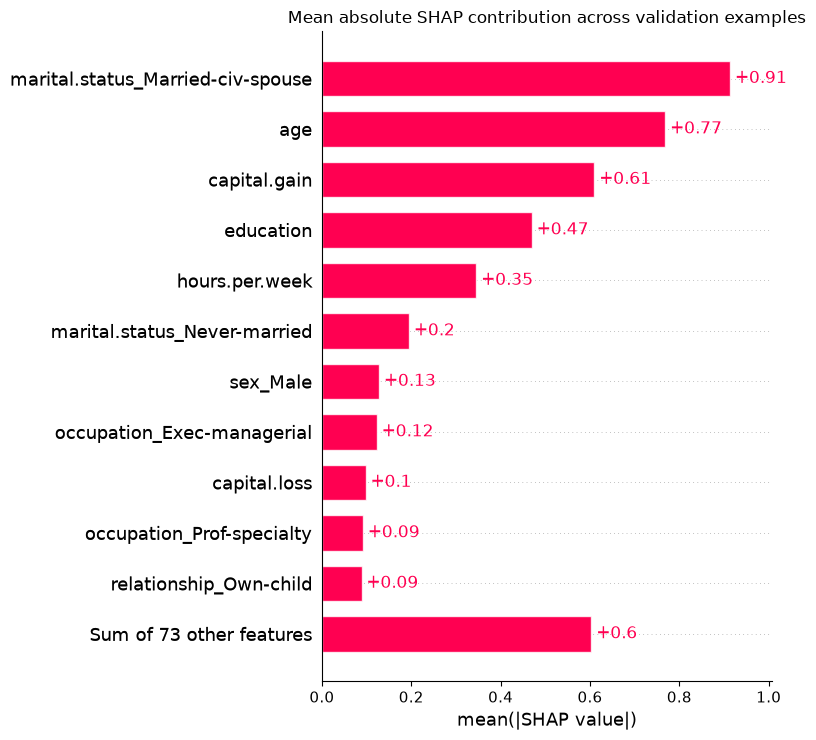

In [24]:
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Mean absolute SHAP contribution across validation examples")
plt.tight_layout()
plt.show()

### SHAP beeswarm: retain direction and variation

- **Dot:** one example; **horizontal position:** signed contribution.
- **Colour:** transformed feature value; indicator high = category present.
- Vertical spreading shows overlap; order uses mean absolute contribution.

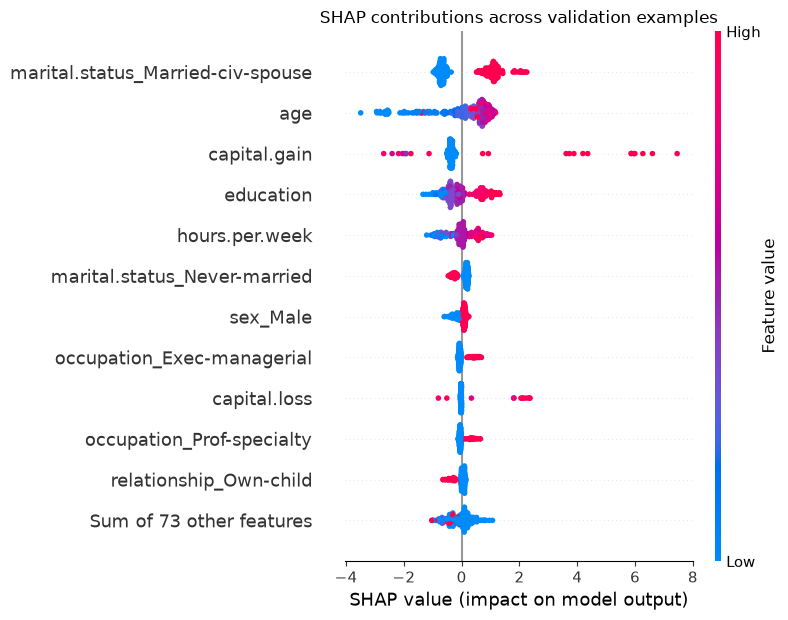

In [25]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP contributions across validation examples")
plt.tight_layout()
plt.show()

**Reading a few features:** right of zero pushes the predicted probability of `>50K` upward; left of zero pushes it downward. The horizontal distances measure contributions in **log-odds**, so a SHAP value of $+1$ does not mean a fixed percentage-point increase in probability.

- **Marital status (`marital.status_Married-civ-spouse`):** this is a binary indicator. Pink/red dots (1 = married with a civilian spouse) lie to the right of zero, pushing the predicted probability of `>50K` upward. Blue dots (0 = not in this category) lie to the left, pushing it downward. This is a particularly clear separation in this sample.
- **Education:** higher education levels (pink/red dots) generally contribute positively, while lower levels (blue dots) generally contribute negatively. Colour represents the ordered education code.
- **Age:** younger people (blue dots) often have negative contributions, sometimes strongly so. Older people (pink/red dots) tend to have modest positive contributions; the pattern is not a simple straight-line relationship.
- **Capital gain:** many low values (blue dots) have small negative contributions. Some higher values (pink/red dots) have very large positive contributions, but others have negative contributions. A high capital gain does not always receive the same contribution.

- Contributions vary across people because the model can learn nonlinear patterns and interactions. These patterns describe the fitted model, not causal effects.
- Final grouped row combines smaller contributions.

**Discuss:** Do all high capital gains receive the same contribution?

### Inspect one feature

- **x:** standardized age; **y:** SHAP contribution.
- The SHAP values reveal a **nonlinear pattern learned by the model** between age and predicted income:
  - **Young:** mostly negative contributions, pushing the predicted probability of `>50K` downward.
  - **Middle-aged:** mostly positive contributions, pushing the predicted probability upward.
  - **Older:** contributions tend to become smaller, though most remain positive in this sample.
- The contribution rises and then tapers off: each extra year does not have the same effect on the model's score.
- Vertical spread at similar ages can reflect interactions.
- Does not estimate the causal effect of becoming older.

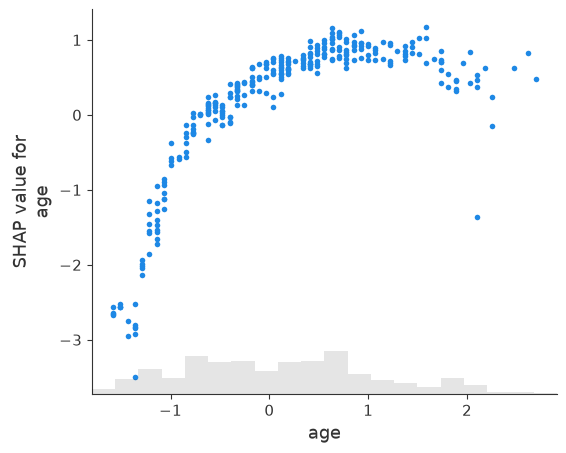

In [26]:
shap.plots.scatter(shap_values[:, "age"])

## 7. Check your interpretation

- Two correlated inputs have near-zero permutation importance. Remove both?
- SHAP base −1.0, contributions +0.8, +0.5, −0.3: raw score? Probability?
- Does a positive coefficient or SHAP value establish causation?

<details>
<summary>Reveal answers</summary>

- **Re-evaluate:** compare refitted pipelines; the inputs may substitute.
- **Raw score = 0; probability = 0.5.** Positive contributions push probability upward and negative contributions push it downward; add contributions on the log-odds scale, then apply sigmoid to the total.
- **No:** these explain a fitted model relative to its representation and reference.

</details>

- Investigate leakage and surprising predictions; validate revised pipelines.
- Keep test data for final assessment; interpretation does not establish fairness.